# Human Activity Recognition (UCI HAR) — full project notebook

**Goal:** predict which of 6 activities a person is doing from smartphone accelerometer + gyroscope data.

**Flow:** 1. Load data → 2. Preprocessing checks → 3. Exploratory data analysis (graphs) → 4. Model comparison → 5. Final evaluation → 6. Conclusions

In [1]:
import json, urllib.request, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")
ROOT = Path.cwd() if (Path.cwd() / "app.py").exists() else Path.cwd().parent
DATA = ROOT / "data" / "UCI HAR Dataset"
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
def save(name): plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

## 1. Load the data
The dataset is downloaded automatically from the UCI repository if it is not already in `data/`.

In [2]:
if not DATA.exists():
    url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
    (ROOT / "data").mkdir(exist_ok=True)
    outer = ROOT / "data" / "har_outer.zip"
    urllib.request.urlretrieve(url, outer)
    with zipfile.ZipFile(outer) as z: z.extractall(ROOT / "data")
    inner = ROOT / "data" / "UCI HAR Dataset.zip"
    if inner.exists():
        with zipfile.ZipFile(inner) as z: z.extractall(ROOT / "data")

def load_split(split):
    X = pd.read_csv(DATA / split / f"X_{split}.txt", sep=r"\s+", header=None)
    y = pd.read_csv(DATA / split / f"y_{split}.txt", header=None)[0]
    s = pd.read_csv(DATA / split / f"subject_{split}.txt", header=None)[0]
    return X, y, s

features = pd.read_csv(DATA / "features.txt", sep=r"\s+", header=None)[1]
labels = pd.read_csv(DATA / "activity_labels.txt", sep=r"\s+", header=None, index_col=0)[1]
class_names = list(labels.values)
X_train, y_train, subj_train = load_split("train")
X_test, y_test, subj_test = load_split("test")
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Activities:", class_names)

Train: (7352, 561) | Test: (2947, 561)
Activities: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


## 2. Preprocessing

The dataset authors already did the signal processing: noise filtering, splitting into 2.56 s windows (128 readings, 50% overlap), separating body motion from gravity, and computing 561 features per window. Our preprocessing therefore is about **checking and preparing** those features.

### 2.1 Feature names — duplicates
`features.txt` contains repeated names, so we make them unique by adding the column number.

In [3]:
print("Total feature names:", len(features), "| unique:", features.nunique())
feature_names = [f"{n}_{i}" if features.duplicated(keep=False)[i] else n for i, n in enumerate(features)]
X_train.columns = feature_names; X_test.columns = feature_names
print("Unique after fix:", len(set(feature_names)))
X_train.iloc[:5, :6]

Total feature names: 561 | unique: 477
Unique after fix: 561


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482


### 2.2 Missing values, duplicate rows, value range

In [4]:
checks = pd.DataFrame({
    "missing values": [int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum())],
    "duplicate rows": [int(X_train.duplicated().sum()), int(X_test.duplicated().sum())],
    "min value": [X_train.values.min(), X_test.values.min()],
    "max value": [X_train.values.max(), X_test.values.max()],
}, index=["train", "test"])
checks

,missing values,duplicate rows,min value,max value
train,0,0,-1.0,1.0
test,0,0,-1.0,1.0


No missing values and every feature is already normalised to [-1, 1]. No imputation or outlier removal is needed.

### 2.3 Label mapping and subject split
Labels 1–6 map to activity names. Train and test must contain **different people**, otherwise test accuracy would be inflated.

In [5]:
print(labels.to_dict())
print("Train subjects:", sorted(int(s) for s in subj_train.unique()))
print("Test subjects :", sorted(int(s) for s in subj_test.unique()))
print("Overlap:", set(subj_train) & set(subj_test))

{1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}
Train subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Test subjects : [2, 4, 9, 10, 12, 13, 18, 20, 24]
Overlap: set()


### 2.4 Feature scaling
Although values lie in [-1, 1], the features have different means and spreads. Logistic Regression and SVM work better when every feature has mean 0 and standard deviation 1, so we use `StandardScaler`. It sits **inside the sklearn pipeline**, so it is fitted on training data only — no information leaks from validation or test data.

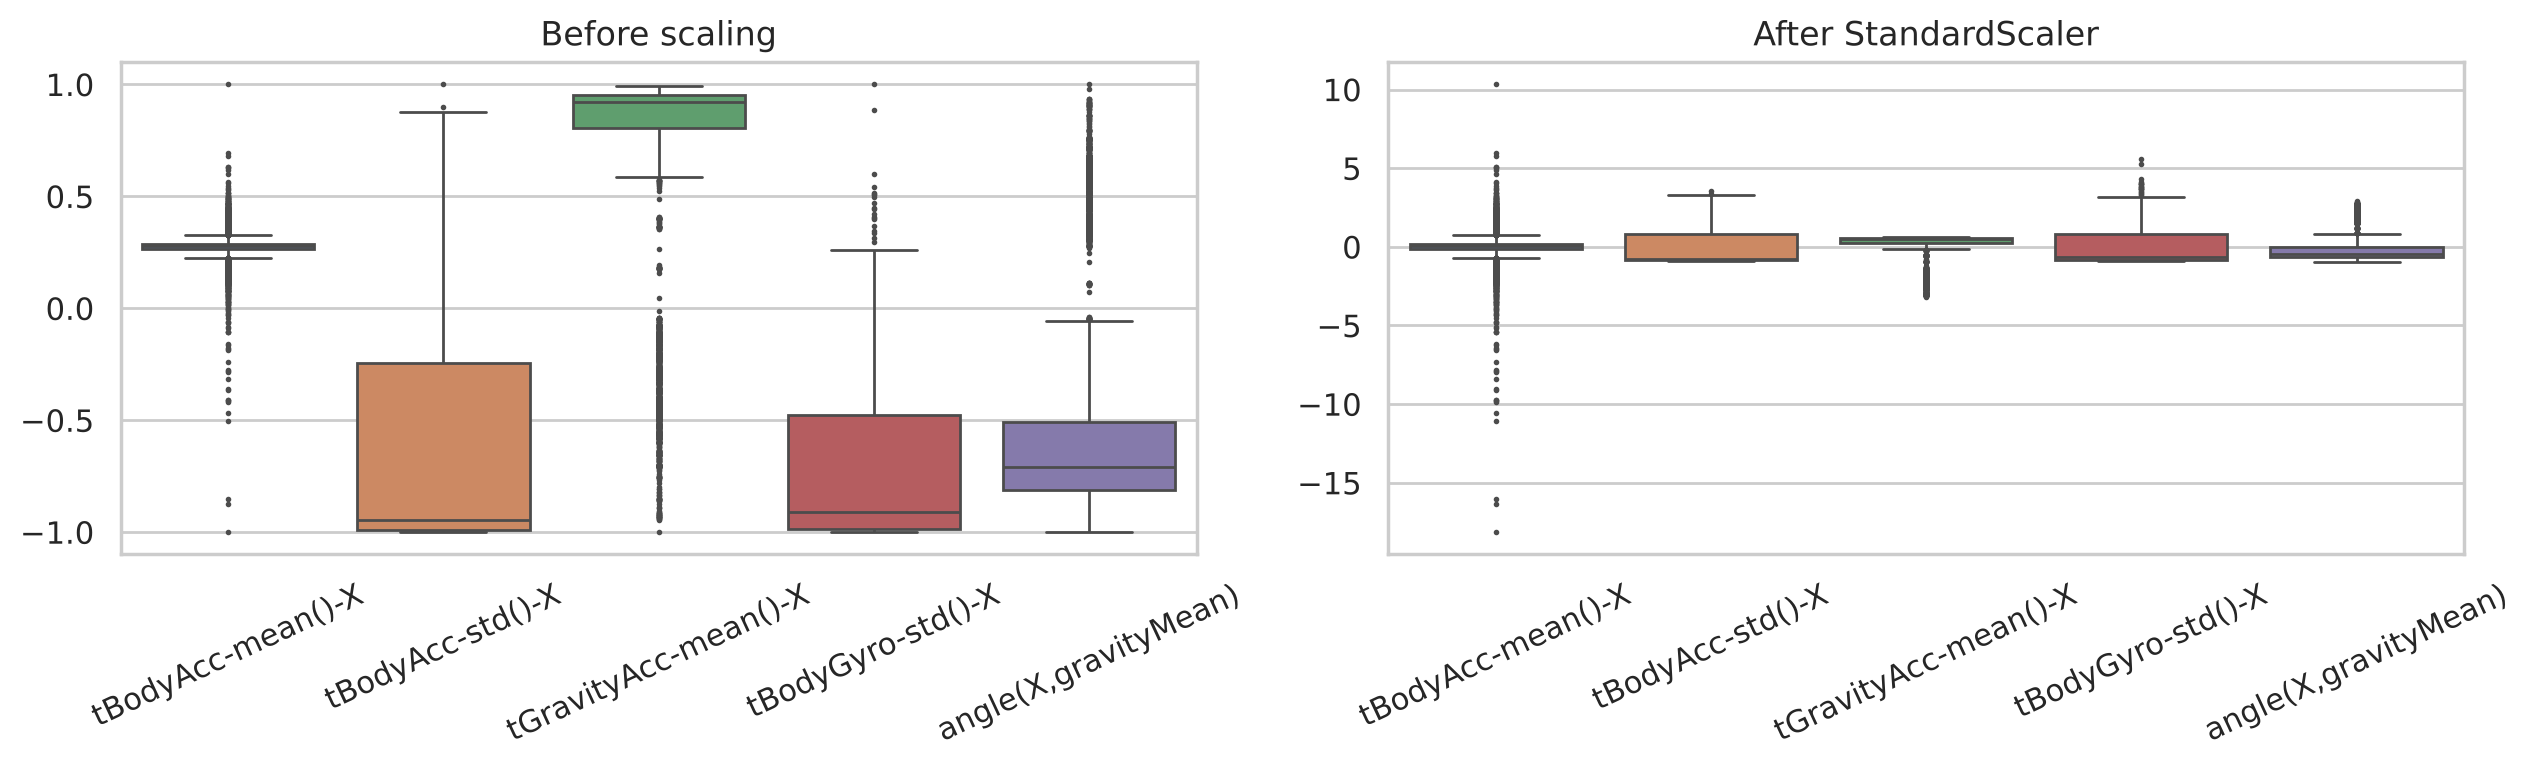

In [6]:
sample = ["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "tGravityAcc-mean()-X", "tBodyGyro-std()-X", "angle(X,gravityMean)"]
scaled = pd.DataFrame(StandardScaler().fit_transform(X_train[sample]), columns=sample)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=X_train[sample], ax=ax[0], fliersize=1); ax[0].set_title("Before scaling")
sns.boxplot(data=scaled, ax=ax[1], fliersize=1); ax[1].set_title("After StandardScaler")
for a in ax: a.tick_params(axis="x", rotation=25)
save("01_scaling_before_after.png")

## 3. Exploratory data analysis
### 3.1 Class distribution — is the data balanced?

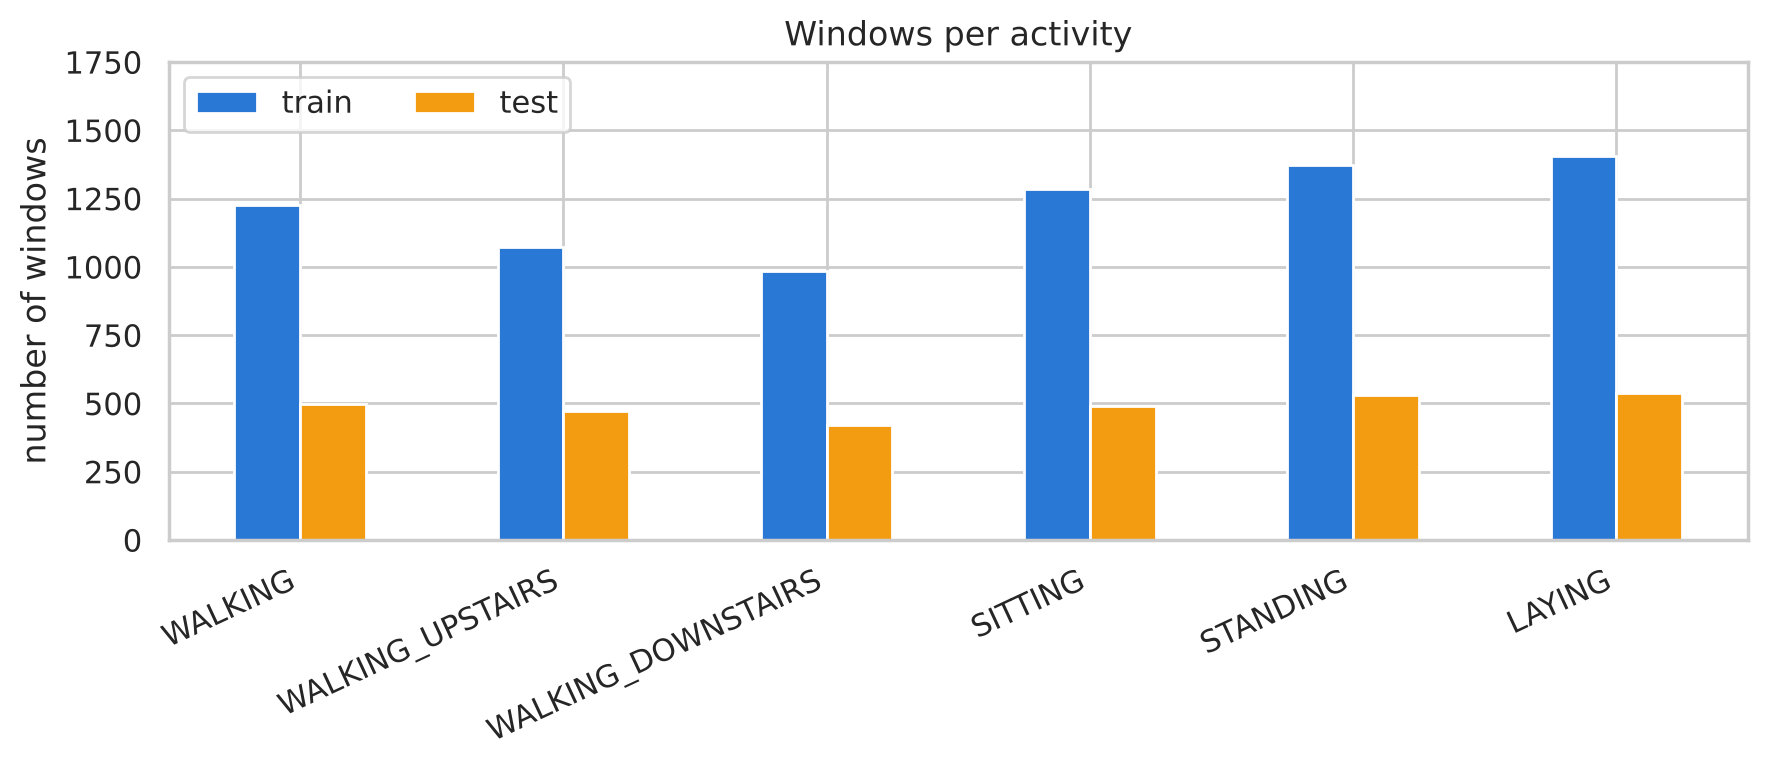

,train,test
0,,
WALKING,1226,496
WALKING_UPSTAIRS,1073,471
WALKING_DOWNSTAIRS,986,420
SITTING,1286,491
STANDING,1374,532
LAYING,1407,537


In [7]:
counts = pd.DataFrame({"train": y_train.map(labels).value_counts(), "test": y_test.map(labels).value_counts()}).loc[class_names]
ax = counts.plot(kind="bar", figsize=(9, 4), color=["#2a78d6", "#f39c12"])
ax.set_ylabel("number of windows"); ax.set_xlabel(""); ax.set_title("Windows per activity"); ax.set_ylim(0, 1750); ax.legend(ncol=2, loc="upper left"); plt.xticks(rotation=25, ha="right")
save("02_class_distribution.png"); counts

The classes are roughly balanced, so accuracy is a fair metric and no resampling is needed.

### 3.2 Windows per subject

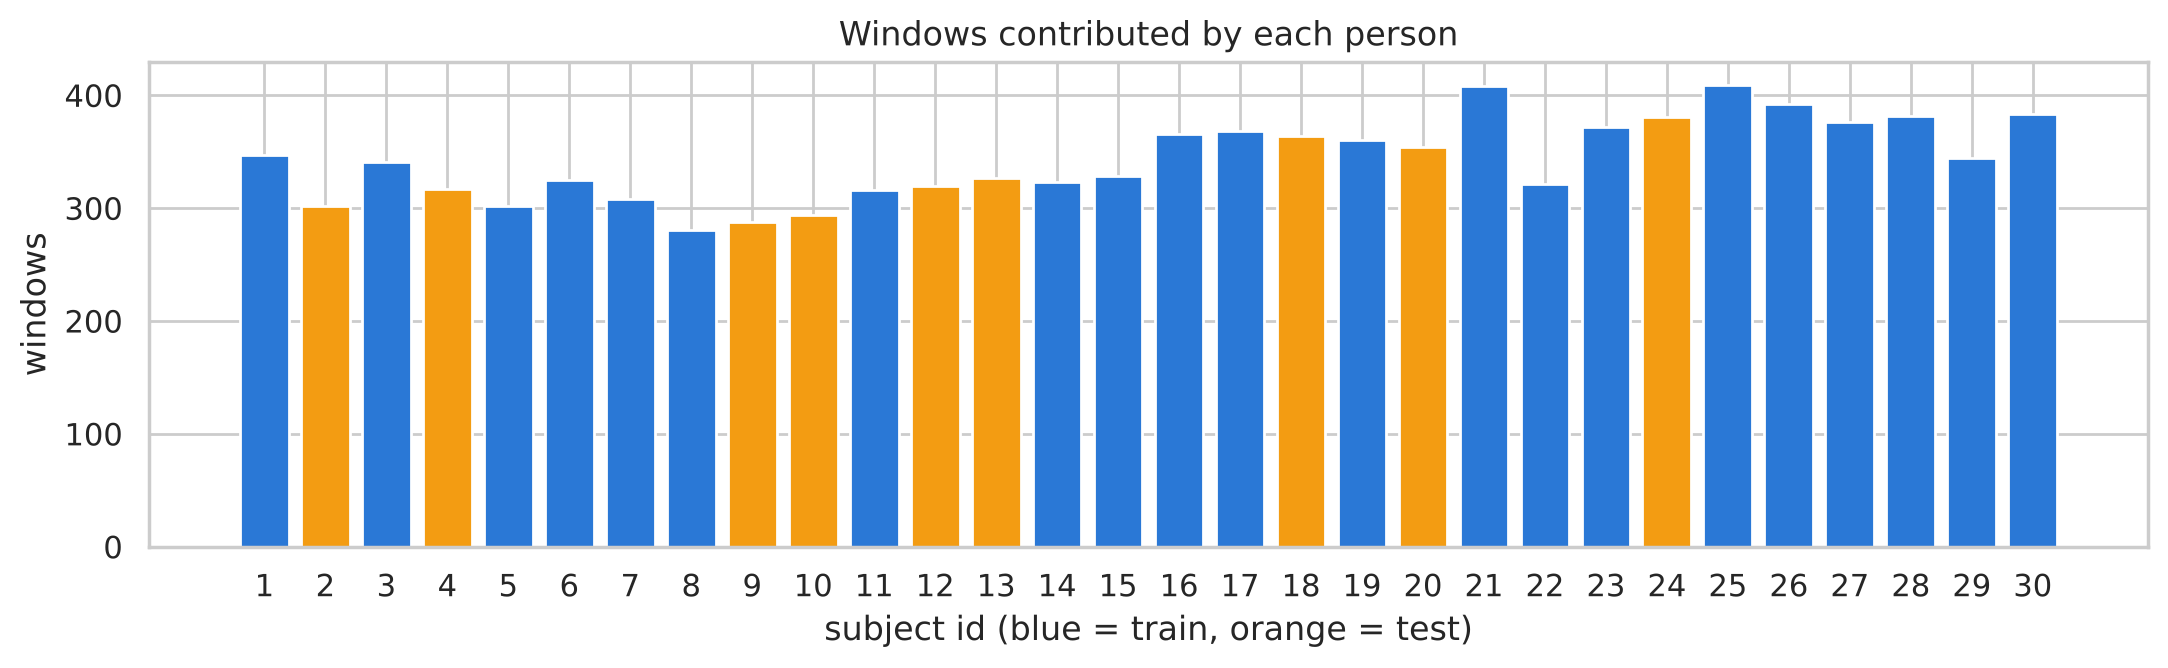

In [8]:
ps = pd.concat([subj_train, subj_test]).value_counts().sort_index()
colors = ["#f39c12" if s in set(subj_test) else "#2a78d6" for s in ps.index]
plt.figure(figsize=(11, 3.5)); plt.bar(ps.index.astype(str), ps.values, color=colors)
plt.xlabel("subject id (blue = train, orange = test)"); plt.ylabel("windows"); plt.title("Windows contributed by each person")
save("03_windows_per_subject.png")

### 3.3 Raw sensor signals
One 2.56 s window of body acceleration for each activity. Moving activities show rhythmic waves; still activities are almost flat. This is why moving vs still is easy and sitting vs standing is hard.

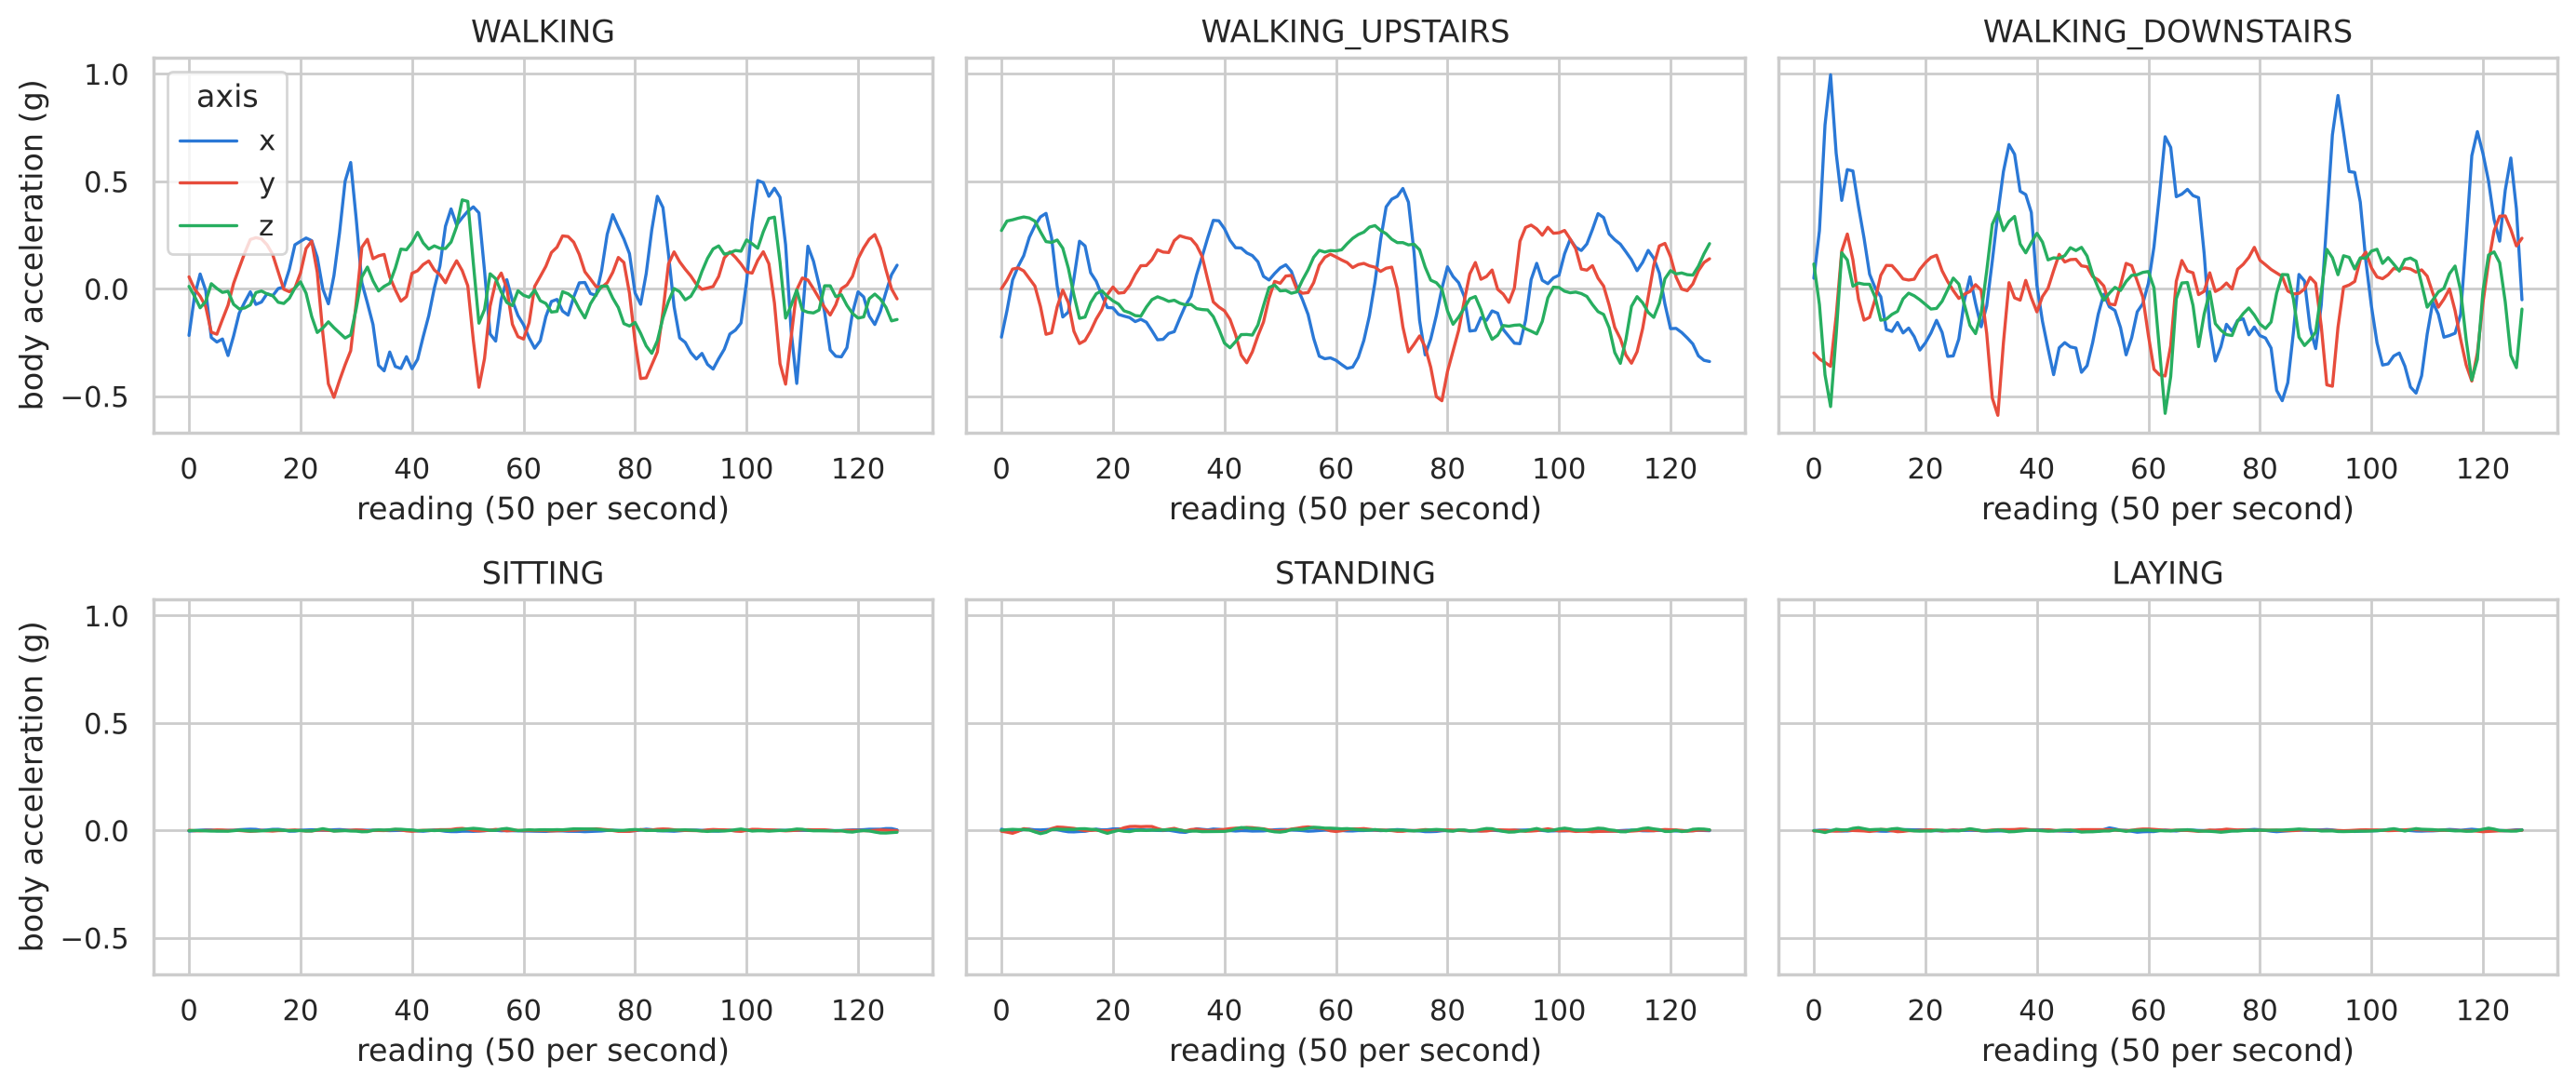

In [9]:
sig = {a: pd.read_csv(DATA / "train" / "Inertial Signals" / f"body_acc_{a}_train.txt", sep=r"\s+", header=None).values for a in "xyz"}
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for ax, (code_, name) in zip(axes.ravel(), labels.items()):
    i = y_train[y_train == code_].index[10]
    for a, c in zip("xyz", ["#2a78d6", "#e74c3c", "#27ae60"]): ax.plot(sig[a][i], label=a, color=c, lw=1.2)
    ax.set_title(name); ax.set_xlabel("reading (50 per second)")
axes[0, 0].set_ylabel("body acceleration (g)"); axes[1, 0].set_ylabel("body acceleration (g)"); axes[0, 0].legend(title="axis")
save("04_raw_signals_per_activity.png")

### 3.4 Key features by activity

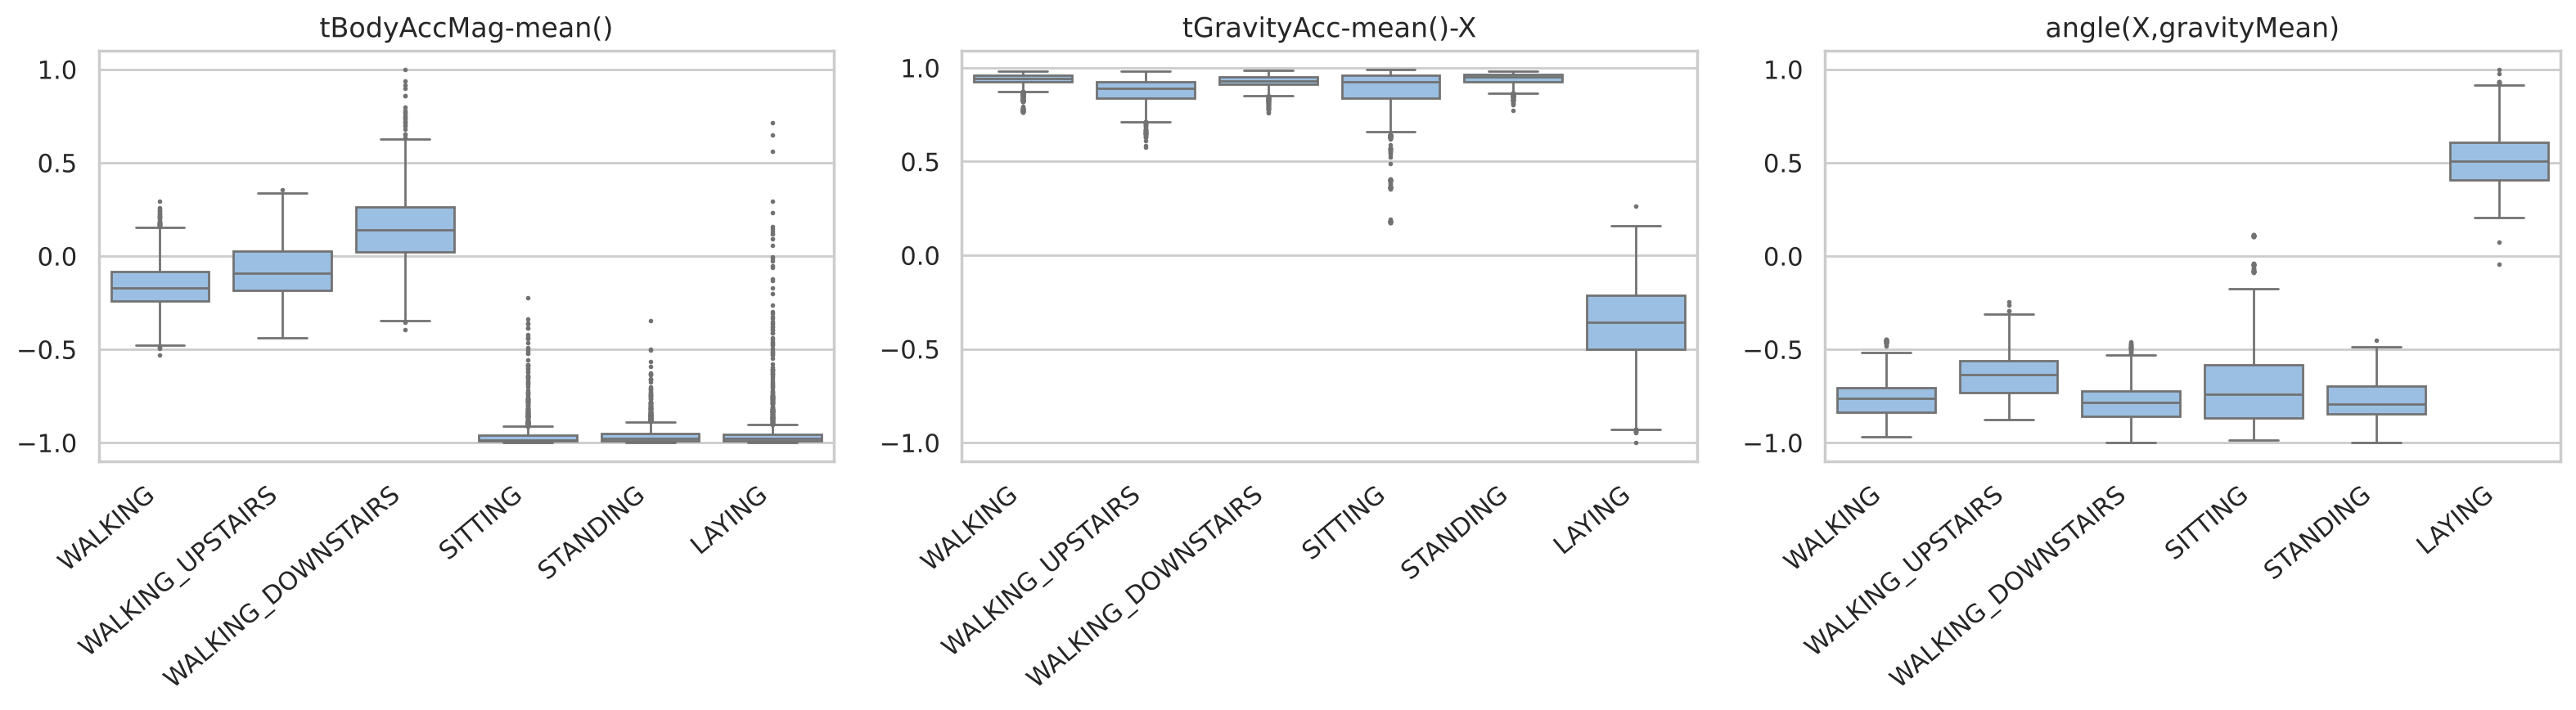

In [10]:
key = ["tBodyAccMag-mean()", "tGravityAcc-mean()-X", "angle(X,gravityMean)"]
d = X_train[key].assign(activity=y_train.map(labels))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axes, key):
    sns.boxplot(data=d, x="activity", y=k, order=class_names, ax=ax, fliersize=1, color="#8fbfee")
    ax.set_title(k); ax.set_xlabel(""); ax.set_ylabel(""); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save("05_key_features_by_activity.png")

`tBodyAccMag-mean()` (how much the body moves) separates moving from still activities. The gravity features separate LAYING, because the phone's orientation changes when you lie down.

### 3.5 Correlation between features

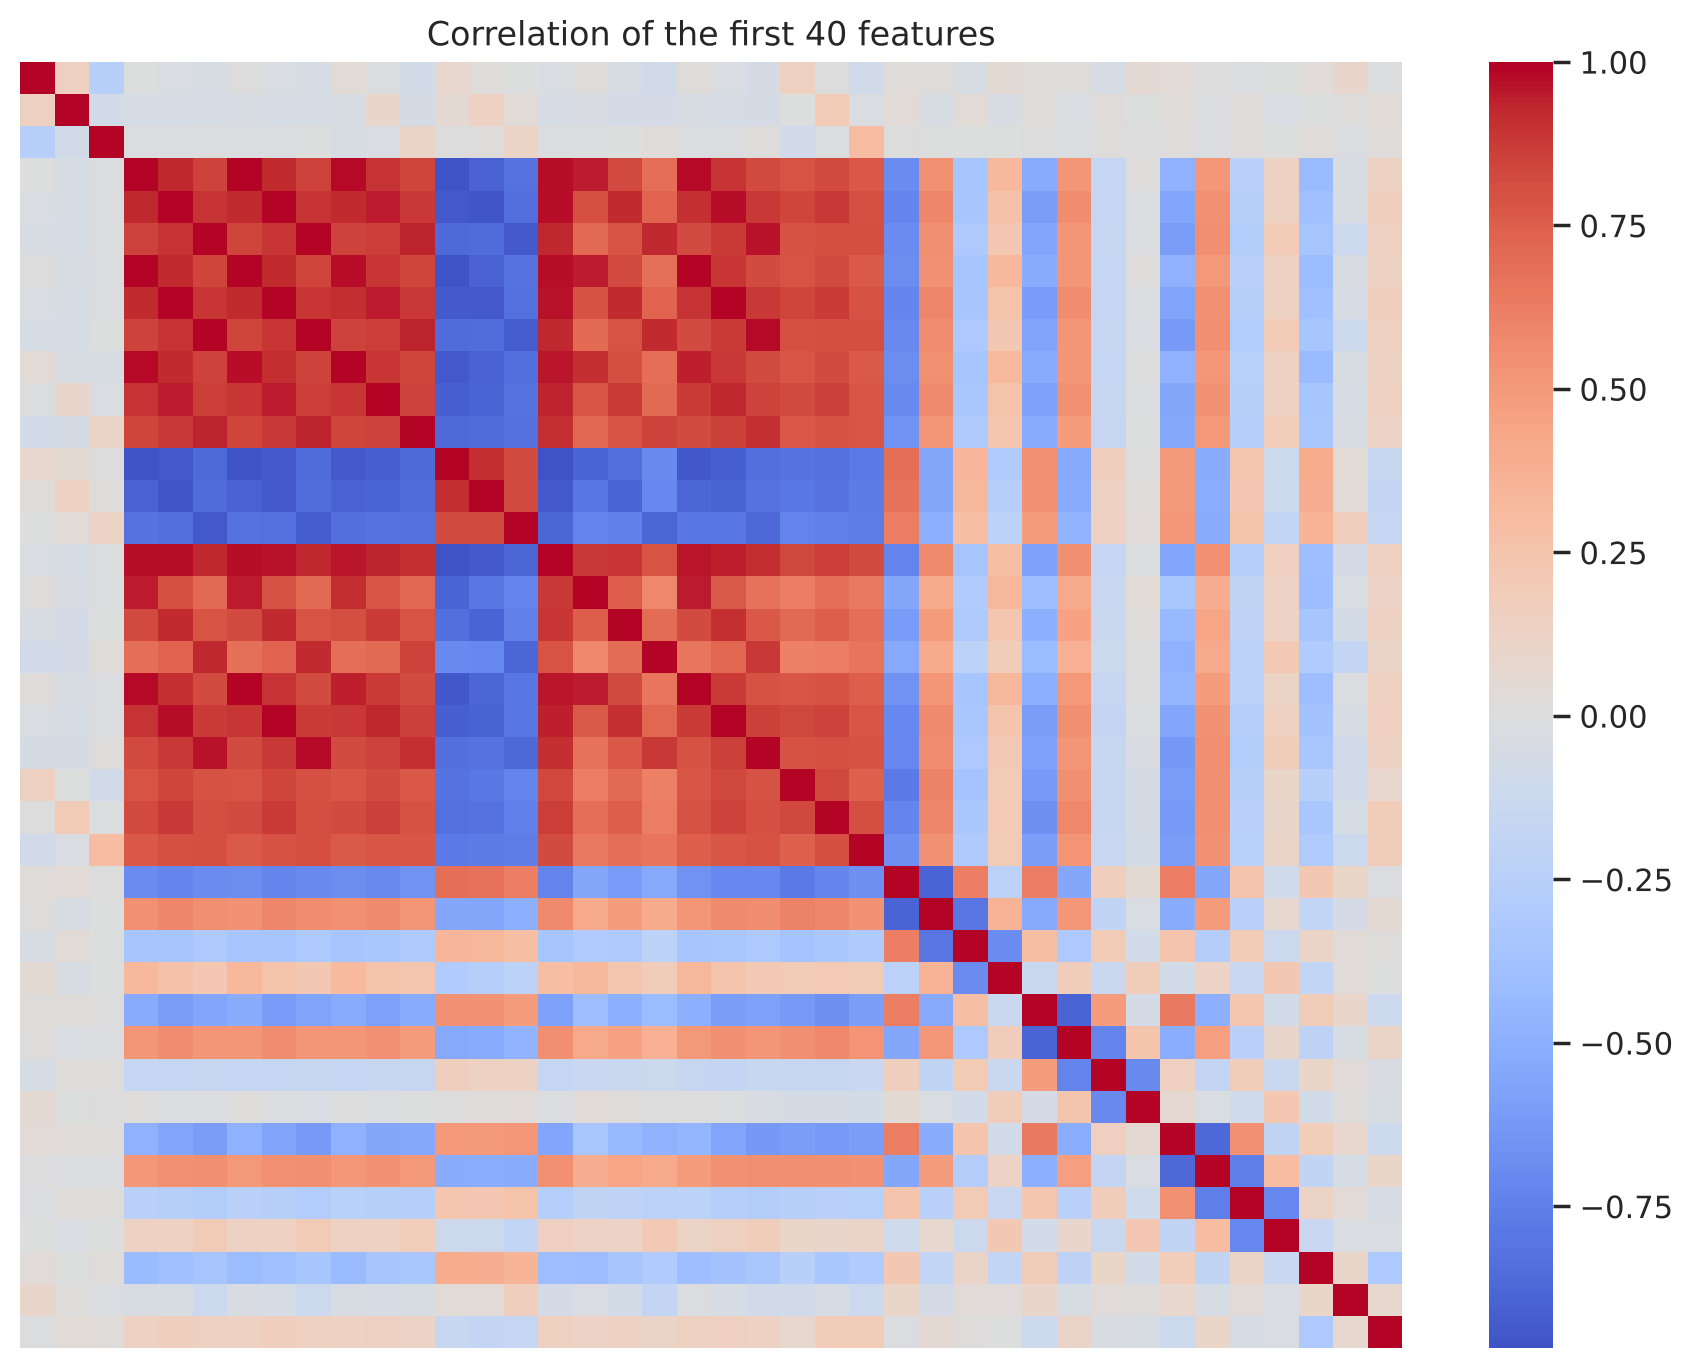

Feature pairs with |correlation| > 0.9: 8,206 of 157,080


In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(X_train.iloc[:, :40].corr(), cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation of the first 40 features")
save("06_correlation_heatmap.png")
corr = X_train.corr().abs().values; iu = np.triu_indices_from(corr, k=1)
print(f"Feature pairs with |correlation| > 0.9: {(corr[iu] > 0.9).sum():,} of {len(iu[0]):,}")

Many features are highly correlated (redundant). That motivates looking at PCA.

### 3.6 PCA — visualising 561 dimensions in 2

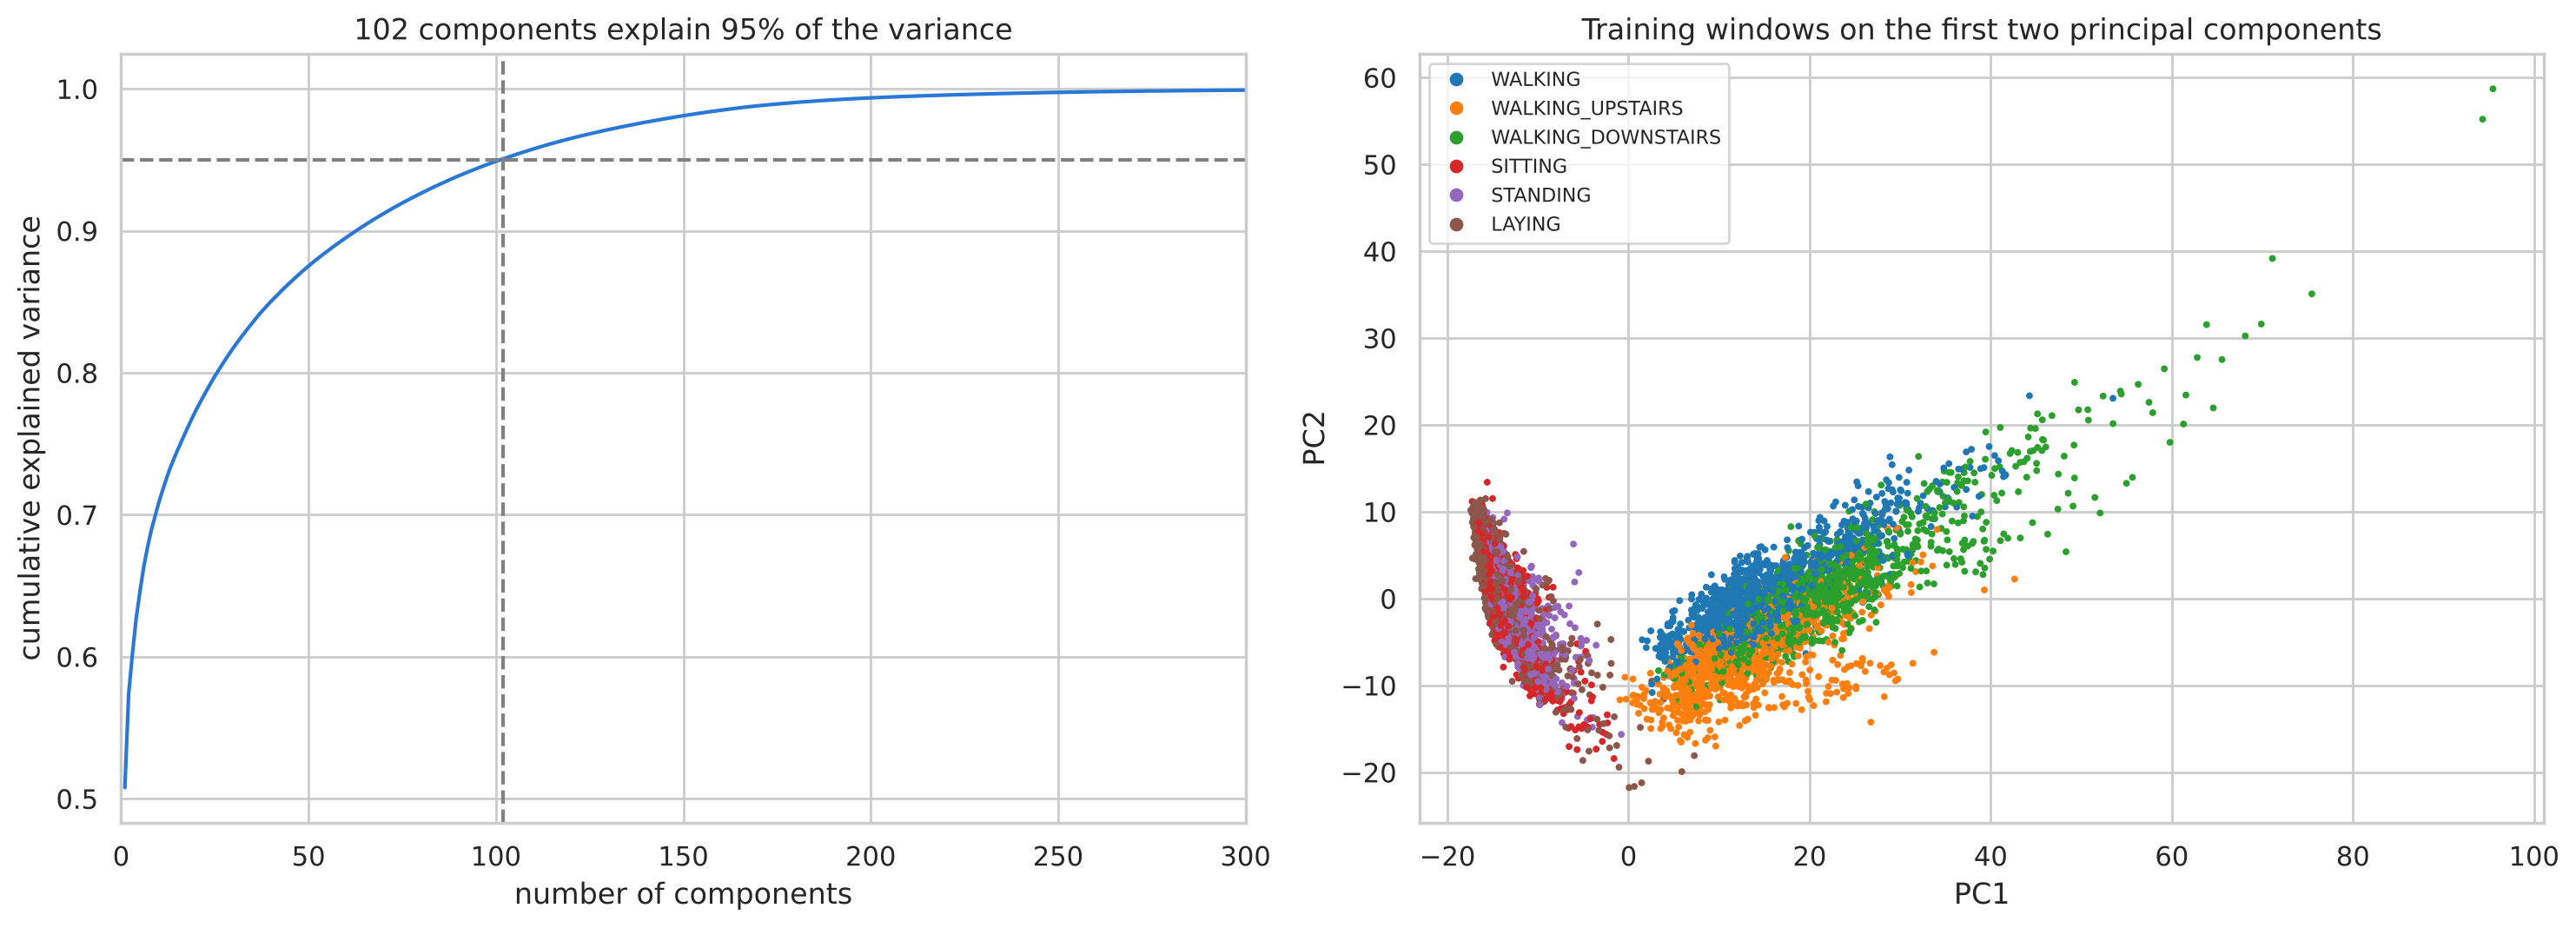

In [12]:
Xs = StandardScaler().fit_transform(X_train)
pca = PCA(random_state=RANDOM_STATE).fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].plot(range(1, len(cum) + 1), cum, color="#2a78d6"); ax[0].axhline(0.95, ls="--", color="grey"); ax[0].axvline(n95, ls="--", color="grey")
ax[0].set_xlim(0, 300); ax[0].set_xlabel("number of components"); ax[0].set_ylabel("cumulative explained variance")
ax[0].set_title(f"{n95} components explain 95% of the variance")
Z = pca.transform(Xs)[:, :2]
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_train.map(labels), hue_order=class_names, s=8, linewidth=0, palette="tab10", ax=ax[1])
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Training windows on the first two principal components"); ax[1].legend(markerscale=2, fontsize=8)
save("07_pca.png")

Moving and still activities form two clearly separate groups. Within the still group, SITTING and STANDING overlap — the same confusion we see later in the model.

## 4. Model comparison
Three models are compared with **5-fold GroupKFold cross-validation grouped by subject**: all windows of one person stay in the same fold, so the validation score reflects performance on new people. The test set is not touched here.

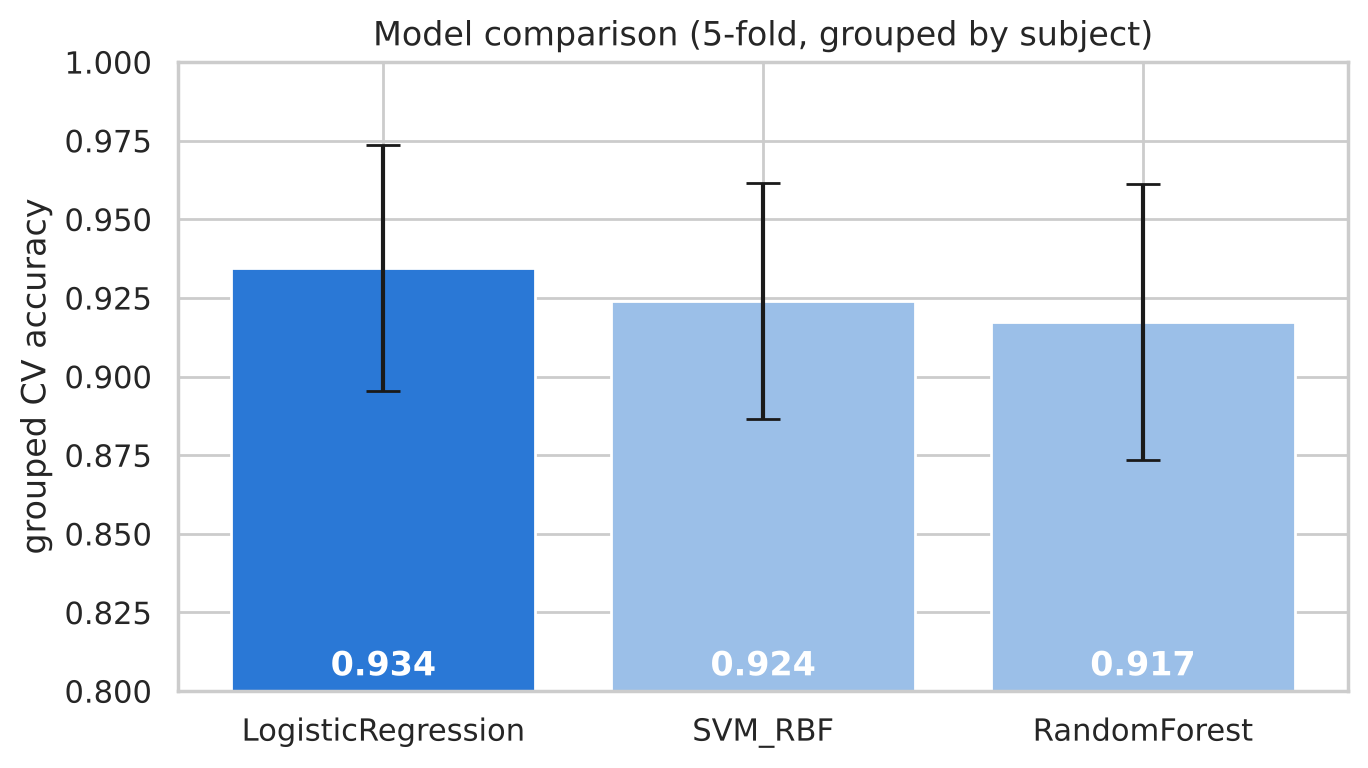

,model,cv_mean,cv_std
0,LogisticRegression,0.934471,0.039132
1,SVM_RBF,0.924055,0.037402
2,RandomForest,0.917319,0.043941


In [13]:
models = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0)),
    "SVM_RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE)),
    "RandomForest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
}
cv = GroupKFold(n_splits=5)
rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train.values, y_train, groups=subj_train, cv=cv, scoring="accuracy")
    rows.append({"model": name, "cv_mean": s.mean(), "cv_std": s.std()})
cv_df = pd.DataFrame(rows).sort_values("cv_mean", ascending=False).reset_index(drop=True)
cv_df.to_csv(ROOT / "outputs" / "model_comparison.csv", index=False)
plt.figure(figsize=(7, 4))
plt.bar(cv_df["model"], cv_df["cv_mean"], yerr=cv_df["cv_std"], capsize=6, color=["#2a78d6", "#9bbfe8", "#9bbfe8"])
for i, v in enumerate(cv_df["cv_mean"]): plt.text(i, 0.805, f"{v:.3f}", ha="center", color="white", fontweight="bold")
plt.ylim(0.8, 1.0); plt.ylabel("grouped CV accuracy"); plt.title("Model comparison (5-fold, grouped by subject)")
save("08_model_comparison.png"); cv_df

## 5. Final evaluation on unseen test subjects
The best model by cross-validation is refitted on all training data and evaluated **once** on the 9 test subjects.

In [14]:
best_name = cv_df.loc[0, "model"]
best = models[best_name].fit(X_train.values, y_train)
y_pred = best.predict(X_test.values)
acc, f1m = accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average="macro")
print(f"Best model: {best_name}\nTest accuracy: {acc:.4f}   macro-F1: {f1m:.4f}\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Best model: LogisticRegression
Test accuracy: 0.9552   macro-F1: 0.9551

                    precision    recall  f1-score   support

           WALKING     0.9444    0.9940    0.9686       496
  WALKING_UPSTAIRS     0.9592    0.9490    0.9541       471
WALKING_DOWNSTAIRS     0.9900    0.9405    0.9646       420
           SITTING     0.9707    0.8758    0.9208       491
          STANDING     0.8872    0.9756    0.9293       532
            LAYING     0.9981    0.9888    0.9935       537

          accuracy                         0.9552      2947
         macro avg     0.9583    0.9539    0.9551      2947
      weighted avg     0.9571    0.9552    0.9552      2947



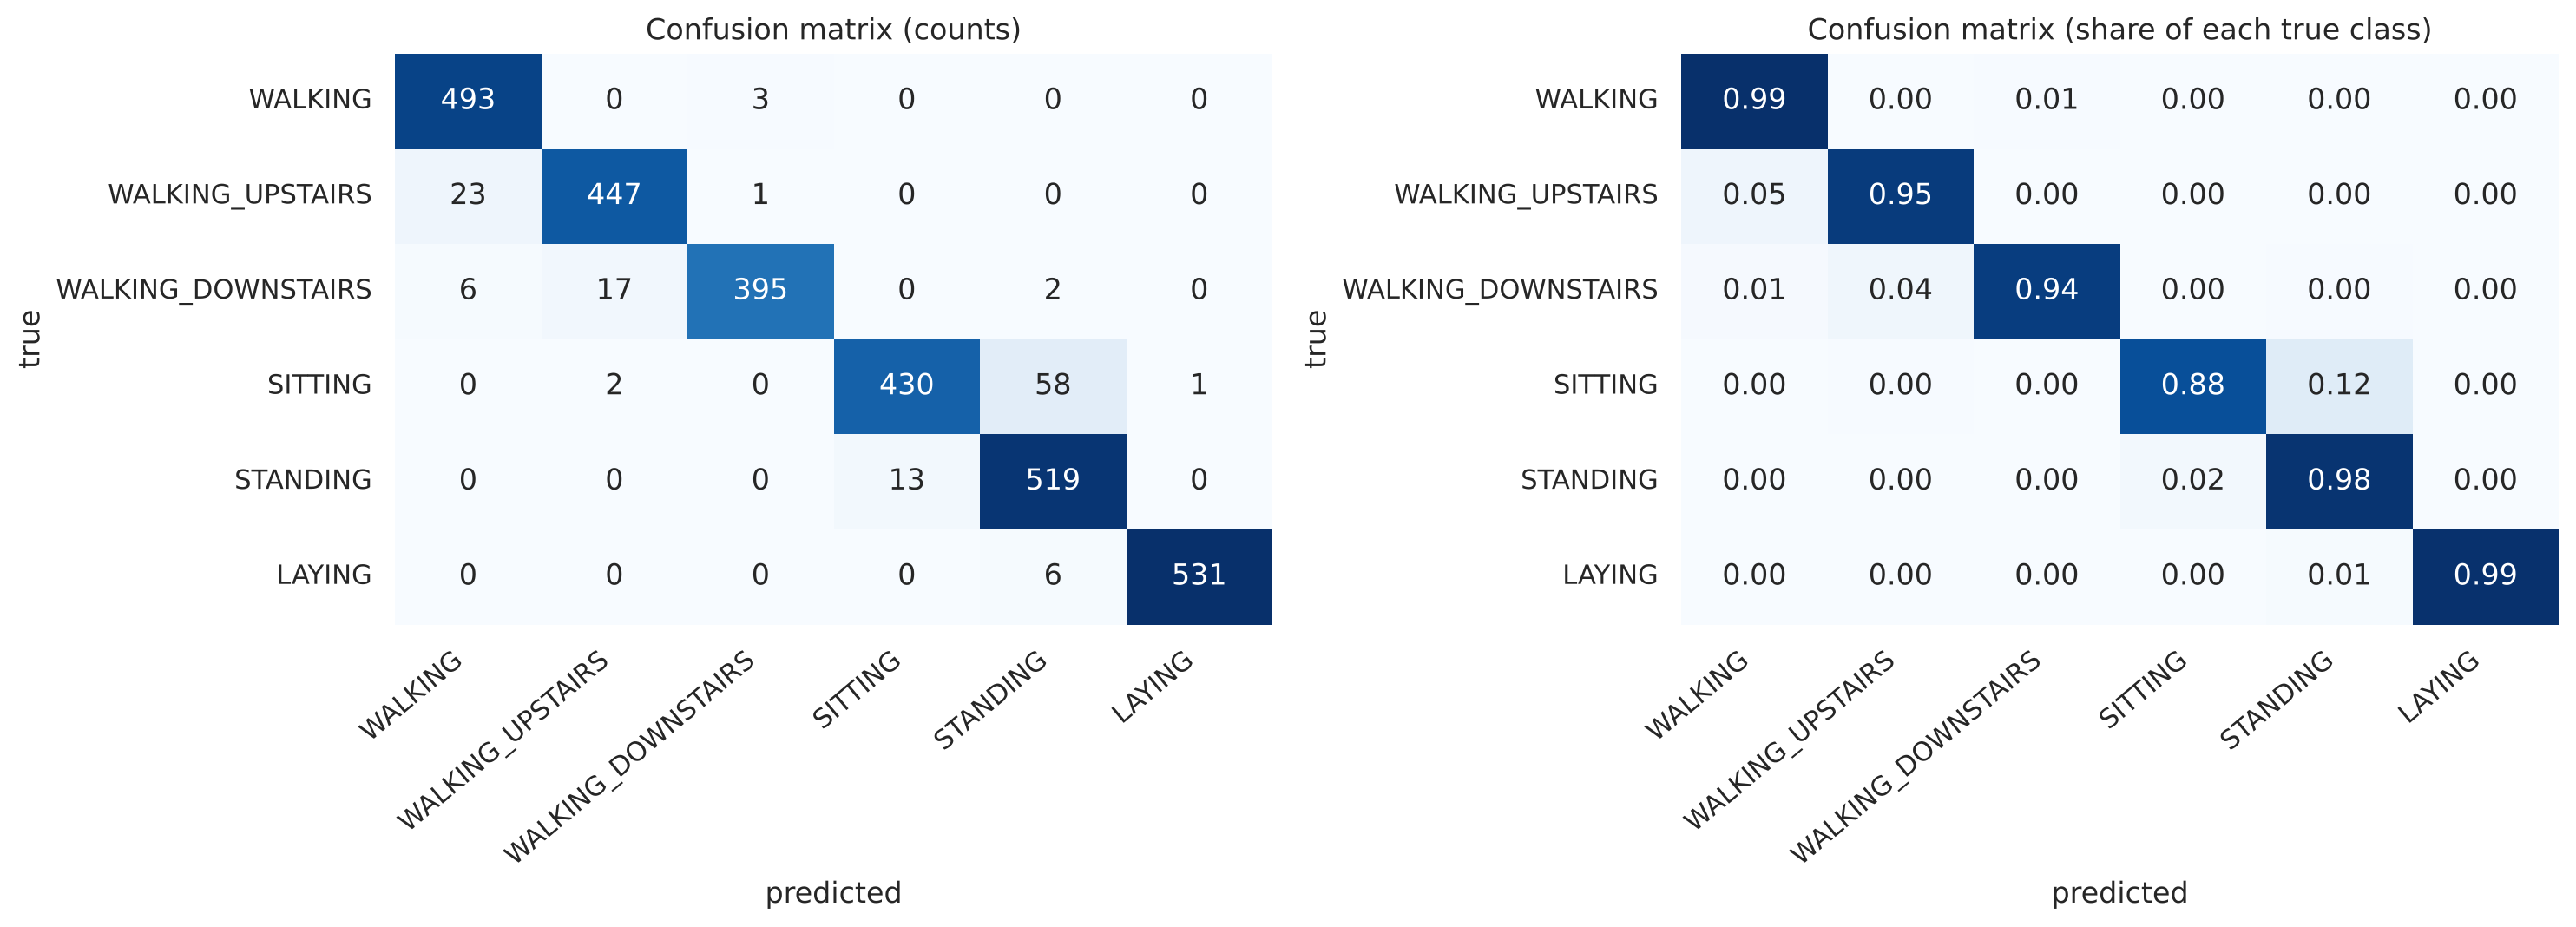

In [15]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Confusion matrix (share of each true class)")
for a in ax: a.set_xlabel("predicted"); a.set_ylabel("true"); plt.setp(a.get_xticklabels(), rotation=40, ha="right")
save("09_confusion_matrices.png")

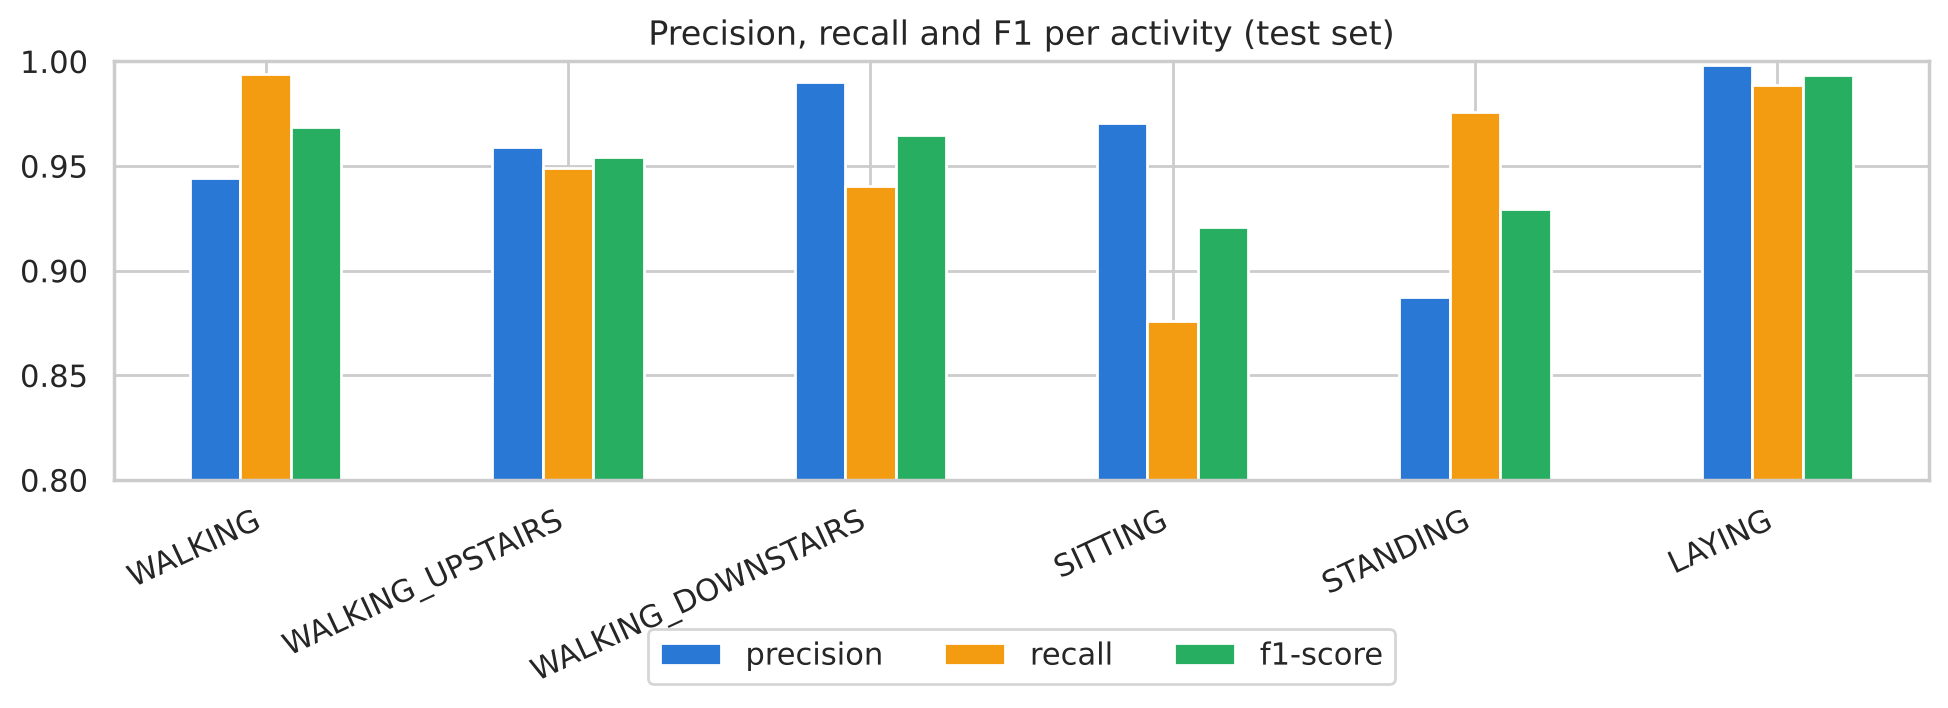

,precision,recall,f1-score
WALKING,0.9444,0.9940,0.9686
WALKING_UPSTAIRS,0.9592,0.9490,0.9541
WALKING_DOWNSTAIRS,0.9900,0.9405,0.9646
SITTING,0.9707,0.8758,0.9208
STANDING,0.8872,0.9756,0.9293
LAYING,0.9981,0.9888,0.9935


In [16]:
rep = pd.DataFrame(classification_report(y_test, y_pred, target_names=class_names, output_dict=True)).T.loc[class_names, ["precision", "recall", "f1-score"]]
ax = rep.plot(kind="bar", figsize=(10, 4), color=["#2a78d6", "#f39c12", "#27ae60"])
ax.set_ylim(0.8, 1.0); ax.set_title("Precision, recall and F1 per activity (test set)"); plt.xticks(rotation=25, ha="right"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32))
save("10_per_class_metrics.png"); rep.round(4)

### Which features matter most?
Random Forest importance, as an independent view of which signals carry the information.

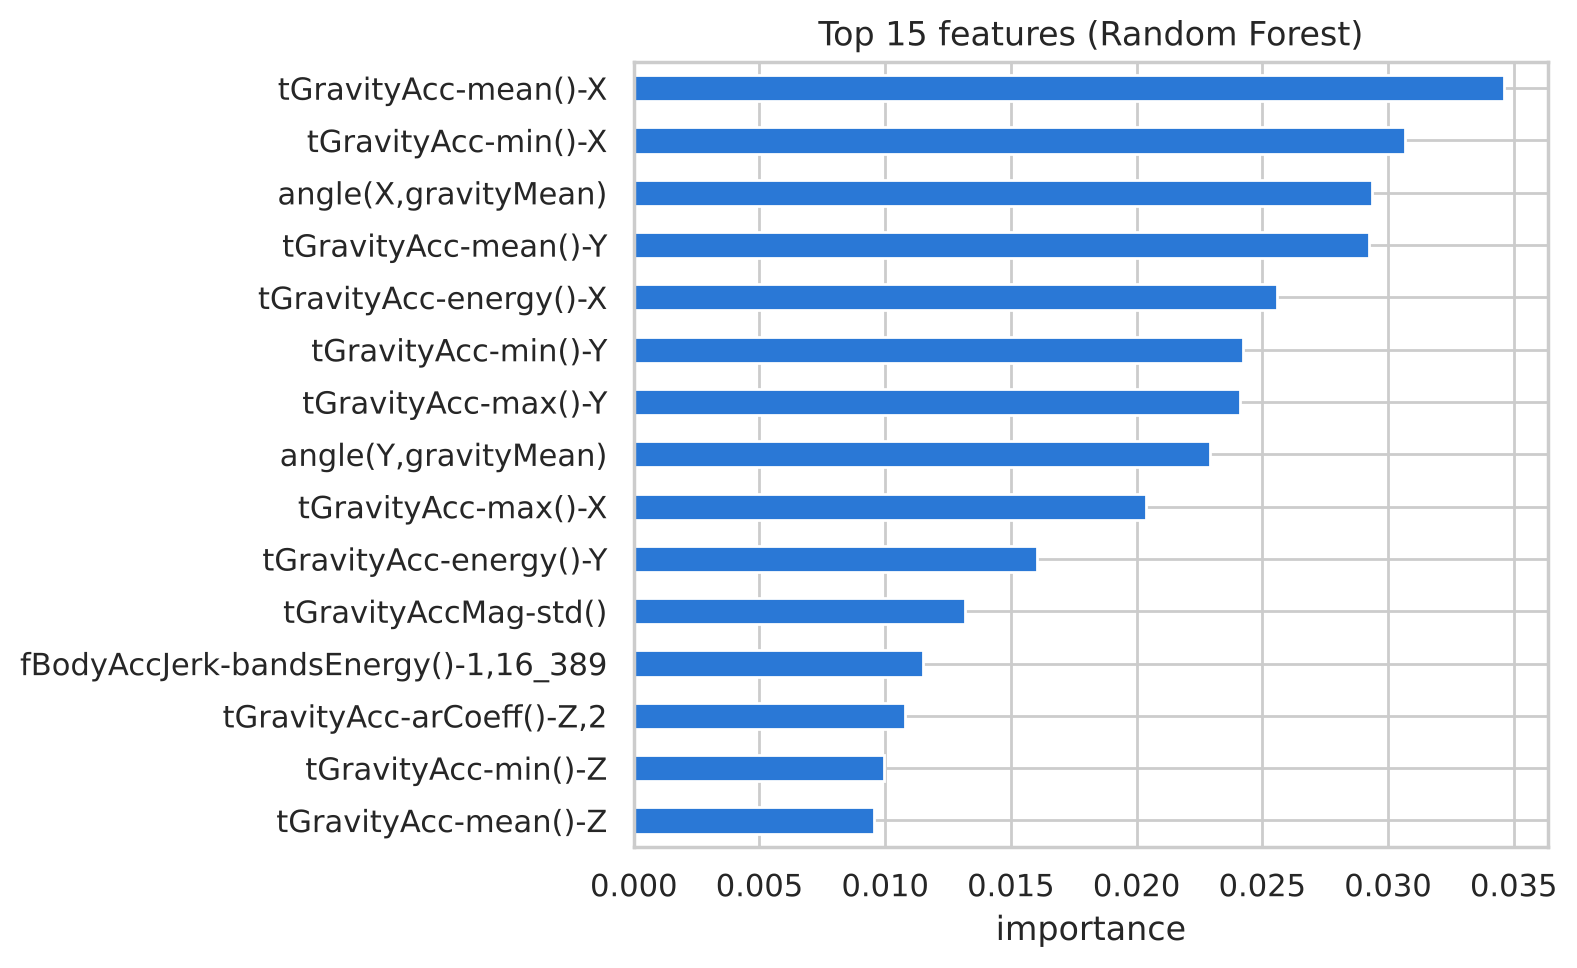

In [17]:
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train.values, y_train)
imp = pd.Series(rf.feature_importances_, index=feature_names).nlargest(15).sort_values()
imp.plot(kind="barh", figsize=(8, 5), color="#2a78d6"); plt.xlabel("importance"); plt.title("Top 15 features (Random Forest)")
save("11_feature_importance.png")

## 6. Conclusions

- The data needed no cleaning: no missing values, already normalised, classes balanced. Preprocessing was de-duplicating feature names, verifying the subject split, and standard scaling inside the pipeline.
- Logistic Regression was the best of three models under subject-grouped cross-validation and generalised to new people on the test set (figures printed above).
- Gravity/orientation features are the most informative. Remaining errors are mostly SITTING vs STANDING, which have almost identical motion.
- **Limitations:** 30 subjects, one phone model, waist-mounted, lab conditions. **Future scope:** compute the features live from a phone, try deep learning (CNN/LSTM) on raw signals, test on other devices and positions.